# DMulti-MADS from Scratch: a List of Incumbents Instead of One

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ahmed-Bayoumy/MECH559/blob/HEAD/L12/L12_dmulti_mads_from_scratch.ipynb)
### MECH 559 - Systems Optimization - L12
### Course Instructor: Dr. Ahmed Bayoumy
Author of the notebook: Dr. Ahmed Bayoumy

Companion notebook to the *DMulti-MADS algorithm* section of the lecture. Single-objective MADS
keeps **one** incumbent and polls around it. With several objectives there is no single best point,
so DMulti-MADS (Bigeon, Le Digabel and Salomon, 2021) keeps a **list** $L^k$ of non-dominated
incumbents, each with its own frame size $\\Delta$. Each iteration picks one of them as the poll
centre, polls around it, and merges the new points into the list.

Before using the OMADS implementation (next notebook), we write the three algorithms of the slides
ourselves, about 80 lines in all, so that nothing OMADS does later is a black box:

- **Algorithm 1**: the main loop (selection, optional search, poll, update);
- **Algorithm 2** `updateList`: how a new point enters the list, and with which frame size;
- **Algorithm 3** `selectCurrentIncumbent`: which point of the list to poll around next, with the
  diversity indicator $\\gamma$.

## Learning objectives

1. Implement `updateList` and relate its three cases to the dominance, extension and densifying zones.
2. Compute the diversity indicator $\\gamma_i$ and use it to choose the next poll centre.
3. Run DMulti-MADS on convex, non-convex and constrained problems and read its list, frame sizes and
   hypervolume.
4. Explain the role of $w^+$ and $\\tau$, and why DMulti-MADS beats random sampling at the same budget.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.rcParams.update({"font.size": 11, "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"list": "#D1495B", "eval": "#9AA0A6", "exact": "#1D5FA8", "random": "#EDAE49",
          "dom": "#2A9D5C", "ext": "#7B2CBF", "dens": "#1D5FA8"}
pd.set_option("display.float_format", lambda v: f"{v:.6g}")

---
## 1. Tools from the previous notebook

Dominance, the non-dominated filter and the 2-objective hypervolume, as defined in the
*Pareto dominance* notebook.

In [2]:
def dominates(fa, fb):
    fa, fb = np.asarray(fa, dtype=float), np.asarray(fb, dtype=float)
    return bool(np.all(fa <= fb) and np.any(fa < fb))


def nondominated(F):
    F = np.asarray(F, dtype=float)
    mask = np.ones(len(F), dtype=bool)
    for i in range(len(F)):
        mask[i] = not (np.all(F <= F[i], axis=1) & np.any(F < F[i], axis=1)).any()
    return mask


def hypervolume_2d(F, ref):
    F = np.asarray(F, dtype=float).reshape(-1, 2)
    F = F[np.all(F < ref, axis=1)]
    if len(F) == 0:
        return 0.0
    F = F[nondominated(F)]
    F = F[np.argsort(F[:, 0])]
    hv, f2_prev = 0.0, ref[1]
    for f1, f2 in F:
        hv += (ref[0] - f1) * (f2_prev - f2)
        f2_prev = f2
    return hv

---
## 2. Algorithm 2: `updateList` and the zones of interest

The list $L^k$ holds pairs $(x, \Delta)$: a non-dominated point and its frame size. When a new
evaluated point $x^j$ (found with frame size $\Delta^j$) arrives, `updateList` checks three cases,
in this order:

| Case | Test | Action | Zone on the slide |
|---|---|---|---|
| 1 | $x^j$ dominates some points of $L^k$ | remove them, add $(x^j, \tau^{-1}\Delta^j)$ | **dominance** zone |
| 2 | $x^j$ improves the best value of some objective, $f_i(x^j) < \min_{x \in L^k} f_i(x)$ | add $(x^j, \tau^{-1}\Delta^j)$ | **extension** zone |
| 3 | $x^j$ is indifferent to every point of $L^k$ | add $(x^j, \Delta^j)$ | **densifying** zone |
| - | otherwise ($x^j$ is dominated by, or equal to, a point of $L^k$) | discard $x^j$ | |

Cases 1 and 2 are real progress: the front moves forward or gets wider. They are rewarded with a
**larger** frame, $\tau^{-1}\Delta^j$ with $\tau \in (0, 1)$, as after a success in single-objective MADS.
Case 3 only fills a gap between existing points, so the frame size is kept.

We store an entry of the list as a tuple `(x, f, Delta)`, with `f` the vector of objectives, so that
we never re-evaluate a point.

In [3]:
def update_list(L, L_add, tau):
    """Algorithm 2. L and L_add are lists of (x, f, Delta); returns the updated list."""
    for x, f, delta in L_add:
        if not np.all(np.isfinite(f)):                                  # infeasible (extreme barrier)
            continue
        if any(dominates(f, fl) for _, fl, _ in L):                     # case 1: dominance zone
            L = [e for e in L if not dominates(f, e[1])] + [(x, f, delta / tau)]
        elif np.any(f < np.min([fl for _, fl, _ in L], axis=0)):        # case 2: extension zone
            L = L + [(x, f, delta / tau)]
        elif all(not dominates(fl, f) and not np.array_equal(fl, f) for _, fl, _ in L):
            L = L + [(x, f, delta)]                                     # case 3: densifying zone
    return L

The figure below is the slide *Zone of interest*: a list of five points and the three zones around
it. We drop one trial point in each zone (and one in the dominated region) and let `update_list`
classify them.

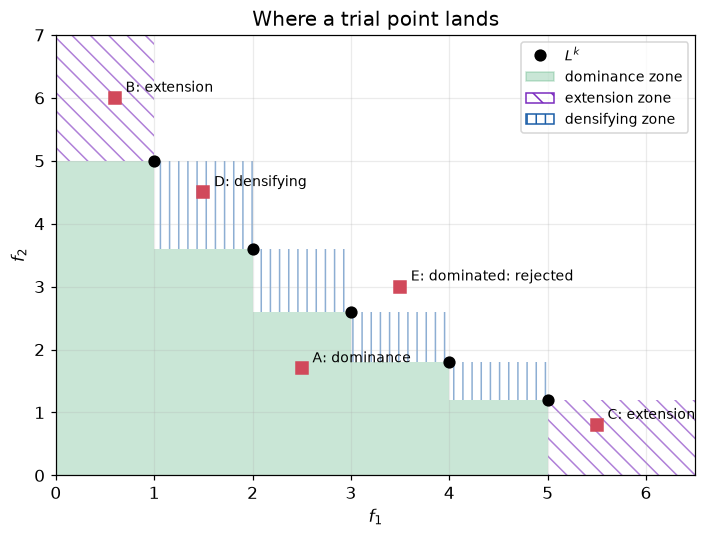

,f1,f2,Delta
4,0.6,6,0.5
0,1,5,0.25
6,1.5,4.5,0.25
1,2,3.6,0.25
3,2.5,1.7,0.5
2,5,1.2,0.25
5,5.5,0.8,0.5


In [4]:
def zone(f, L):
    """Name of the zone of f with respect to the list L (same tests as update_list)."""
    if any(dominates(f, fl) for _, fl, _ in L):
        return "dominance"
    if np.any(f < np.min([fl for _, fl, _ in L], axis=0)):
        return "extension"
    if all(not dominates(fl, f) and not np.array_equal(fl, f) for _, fl, _ in L):
        return "densifying"
    return "dominated: rejected"


F_list = np.array([[1.0, 5.0], [2.0, 3.6], [3.0, 2.6], [4.0, 1.8], [5.0, 1.2]])
L_demo = [(None, f, 0.25) for f in F_list]
trials = {"A": [2.5, 1.7], "B": [0.6, 6.0], "C": [5.5, 0.8], "D": [1.5, 4.5], "E": [3.5, 3.0]}

fig, ax = plt.subplots(figsize=(7.5, 5.2))
stairs = F_list[np.argsort(F_list[:, 0])]
corners = [(0, 0), (0, stairs[0][1])]             # dominance zone: everything below the staircase
for i, (f1, f2) in enumerate(stairs):
    corners += [(f1, f2), (f1, stairs[i + 1][1]) if i + 1 < len(stairs) else (f1, 0)]
    if i + 1 < len(stairs):                       # densifying zone: the gaps of the staircase
        ax.add_patch(mpatches.Rectangle((f1, stairs[i + 1][1]), stairs[i + 1][0] - f1, f2 - stairs[i + 1][1],
                                        facecolor="none", hatch="||", edgecolor=COLORS["dens"], lw=0, alpha=0.5))
ax.add_patch(mpatches.Polygon(corners, closed=True, color=COLORS["dom"], alpha=0.25, lw=0))
ax.add_patch(mpatches.Rectangle((0, stairs[0][1]), stairs[0][0], 7 - stairs[0][1], facecolor="none",
                                hatch="\\\\", edgecolor=COLORS["ext"], lw=0, alpha=0.6))
ax.add_patch(mpatches.Rectangle((stairs[-1][0], 0), 6.5 - stairs[-1][0], stairs[-1][1], facecolor="none",
                                hatch="\\\\", edgecolor=COLORS["ext"], lw=0, alpha=0.6))
ax.plot(*F_list.T, "ko", ms=7, label="$L^k$")
for name, f in trials.items():
    ax.plot(*f, "s", ms=8, color=COLORS["list"])
    ax.annotate(f"{name}: {zone(f, L_demo)}", f, textcoords="offset points", xytext=(7, 4), fontsize=9)
handles = [mpatches.Patch(color=COLORS["dom"], alpha=0.25, label="dominance zone"),
           mpatches.Patch(facecolor="none", hatch="\\\\", edgecolor=COLORS["ext"], label="extension zone"),
           mpatches.Patch(facecolor="none", hatch="||", edgecolor=COLORS["dens"], label="densifying zone")]
ax.legend(handles=[*ax.get_legend_handles_labels()[0], *handles], loc="upper right", fontsize=9)
ax.set(xlim=(0, 6.5), ylim=(0, 7), xlabel="$f_1$", ylabel="$f_2$", title="Where a trial point lands")
plt.show()

L_new = update_list(L_demo, [(None, np.array(f), 0.25) for f in trials.values()], tau=0.5)
pd.DataFrame([{"f1": f[0], "f2": f[1], "Delta": d} for _, f, d in L_new]).sort_values("f1")

Read the table: A removed the two points $(3, 2.6)$ and $(4, 1.8)$ and entered with
$\Delta = 0.5 = 0.25/\tau$; B and C extended the front at its two ends, also with $\Delta = 0.5$; D filled
a gap and kept $\Delta = 0.25$; E was dominated and was discarded.

> **Checkpoint 1.** Point A dominated two points of the list. Why does `update_list` not need to check
> whether A is *also* dominated by another point of the list? *Answer:* the list is non-dominated. If a
> point of $L^k$ dominated A, it would also dominate the two points A dominates (dominance is
> transitive), which is impossible.

---
## 3. Algorithm 3: `selectCurrentIncumbent` and the diversity indicator $\gamma$

Only points whose frame is **not much smaller** than the largest one can be selected:

$$
L^{\text{select}} = \big\{(x, \Delta) \in L^k : \tau^{w^+} \Delta_{\max}^k \le \Delta \le \Delta_{\max}^k\big\}.
$$

$w^+ \in \mathbb{N}$ says how many refinements below the largest frame a point may be: $w^+ = 0$ allows
only the points with the largest frame, a large $w^+$ allows almost all of them. If several points
qualify, Algorithm 3 picks the one around which the front has the **largest gap**, measured for each
objective $i$ on the list sorted by $f_i$:

$$
\gamma_i(x^j) = \begin{cases}
2\,\dfrac{f_i(x^2) - f_i(x^1)}{f_i(x^{|L|}) - f_i(x^1)} & j = 1 \\[1ex]
2\,\dfrac{f_i(x^{|L|}) - f_i(x^{|L|-1})}{f_i(x^{|L|}) - f_i(x^1)} & j = |L| \\[1ex]
\dfrac{f_i(x^{j+1}) - f_i(x^{j-1})}{f_i(x^{|L|}) - f_i(x^1)} & \text{otherwise.}
\end{cases}
$$

The two ends count their single gap twice, so that the extremes of the front are not neglected. With
exactly two points in the list (and both selectable) the formula is degenerate, and the slide picks the
point with the largest objective value instead.

In [5]:
def gamma_indicator(L):
    """gamma[j, i] for every point j of the list and every objective i."""
    F = np.array([f for _, f, _ in L])
    m, p = F.shape
    gam = np.zeros((m, p))
    for i in range(p):
        order = np.argsort(F[:, i], kind="stable")
        fs = F[order, i]
        span = fs[-1] - fs[0]
        if span <= 0:
            continue
        g = np.empty(m)
        g[0] = 2 * (fs[1] - fs[0]) / span
        g[-1] = 2 * (fs[-1] - fs[-2]) / span
        g[1:-1] = (fs[2:] - fs[:-2]) / span
        gam[order, i] = g
    return gam


def select_current(L, w_plus, tau):
    """Algorithm 3: index of the poll centre in L."""
    deltas = np.array([d for _, _, d in L])
    selectable = [j for j in range(len(L)) if deltas[j] >= tau ** w_plus * deltas.max()]
    if len(selectable) == 1:
        return selectable[0]
    if len(selectable) == 2 and len(L) == 2:
        return max(selectable, key=lambda j: np.max(L[j][1]))
    gam = gamma_indicator(L).max(axis=1)              # max over the objectives
    return max(selectable, key=lambda j: gam[j])

The seven points of the slide *Computing the diversity indicator*, with all frames equal:

In [6]:
F7 = np.array([[0.6, 9.4], [1.0, 8.0], [3.6, 4.6], [6.6, 3.8], [7.0, 3.4], [7.4, 2.8], [7.7, 2.2]])
L7 = [(None, f, 1.0) for f in F7]
g7 = gamma_indicator(L7)
j0 = select_current(L7, w_plus=3, tau=0.5)
display(pd.DataFrame(g7, columns=["gamma_1", "gamma_2"], index=[f"x{j + 1}" for j in range(7)]).assign(
    max_gamma=g7.max(axis=1)))
print(f"selected poll centre: x{j0 + 1}, F = {F7[j0]}")

,gamma_1,gamma_2,max_gamma
x1,0.112676,0.388889,0.388889
x2,0.422535,0.666667,0.666667
x3,0.788732,0.583333,0.788732
x4,0.478873,0.166667,0.478873
x5,0.112676,0.138889,0.138889
x6,0.0985915,0.166667,0.166667
x7,0.084507,0.166667,0.166667


selected poll centre: x3, F = [3.6 4.6]


$x^3$ wins: its neighbours in $f_1$ are $x^2$ and $x^4$, far apart, so the front has a large hole there.
Polling around $x^3$ is the best chance to fill it. This is how DMulti-MADS spreads its points along the
front without any explicit spacing rule.

> **Checkpoint 2.** Give $x^3$ a frame size of $0.1$ and the others $1.0$, with $\tau = 0.5$ and $w^+ = 3$.
> Is $x^3$ still selectable? *Answer:* no: $\tau^{w^+}\Delta_{\max} = 0.125 > 0.1$. A point whose
> frame was reduced many times has been polled a lot without success, so the algorithm leaves it alone
> and spends its evaluations elsewhere.

---
## 4. Algorithm 1: the main loop

We now assemble the main loop of the slide *DMulti-MADS with extreme barrier*:

1. **Select** $(x_k, \Delta_k)$ with Algorithm 3. The mesh size is $\delta_k = \min\{\Delta_k, \Delta_k^2\}$.
2. **Search** (optional): skipped here, as in many implementations.
3. **Poll**: evaluate $x_k + \delta_k d$ for the $2n$ directions $d$ of $D = [H, -H]$, where $H$ is a random
   orthogonal (Householder) matrix rounded to the mesh. This is the OrthoMADS poll of the DFO lecture.
4. **Update**: discard the dominated poll points, call `update_list`; if no poll point dominates $x_k$,
   the iteration is unsuccessful and the frame of $x_k$ is reduced to $\tau \Delta_k$.

The **extreme barrier** handles constraints and bounds: an infeasible point gets $F = +\infty$ and never
enters the list. The variables are scaled to $[0, 1]^n$, so a single $\Delta$ works for all of them.
The loop stops at the evaluation budget, or when the selected frame is below `min_delta`.

In [7]:
def dmulti_mads(problem, x0, lb, ub, budget=500, delta0=0.25, tau=0.5, w_plus=3, seed=0, min_delta=1e-6):
    """DMulti-MADS with extreme barrier. problem(x) returns (objectives, constraints <= 0).

    Returns the final list (DataFrame), every evaluation (DataFrame) and one row per iteration.
    """
    rng = np.random.default_rng(seed)
    lb, ub = np.asarray(lb, dtype=float), np.asarray(ub, dtype=float)
    n, evals, cache = len(lb), [], {}

    def f_omega(u):                                   # objectives at the scaled point u, +inf if infeasible
        key = tuple(np.round(u, 12))
        if key not in cache:
            x = lb + u * (ub - lb)
            f, c = problem(x)
            feasible = bool(np.all(u >= 0) and np.all(u <= 1) and all(ci <= 0 for ci in c))
            evals.append(dict(**{f"x{i + 1}": x[i] for i in range(n)}, f1=f[0], f2=f[1], feasible=feasible))
            cache[key] = np.asarray(f, dtype=float) if feasible else np.full(len(f), np.inf)
        return cache[key]

    u0 = (np.asarray(x0, dtype=float) - lb) / (ub - lb)
    L, history = [(u0, f_omega(u0), delta0)], []
    while len(evals) < budget:
        # 1. selection of the poll centre (Algorithm 3)
        j = select_current(L, w_plus, tau)
        uk, fk, Dk = L[j]
        if Dk < min_delta:
            break
        dk = min(Dk, Dk ** 2)
        # 3. poll: 2n orthogonal directions on the mesh, of length about Delta_k
        v = rng.normal(size=n)
        H = np.eye(n) - 2 * np.outer(v, v) / (v @ v)
        H = np.round(H / np.max(np.abs(H), axis=0) * (Dk / dk))
        L_add, success = [], False
        for d in np.hstack([H, -H]).T:
            if len(evals) >= budget:
                break
            t = uk + dk * d
            ft = f_omega(t)
            L_add.append((t, ft, Dk))
            success = success or dominates(ft, fk)
        # 4. update (Algorithm 2)
        L_add = [e for e in L_add if np.all(np.isfinite(e[1]))]
        if L_add:
            L_add = [e for e, keep in zip(L_add, nondominated([e[1] for e in L_add])) if keep]
        L = update_list(L, L_add, tau)
        if not success:                               # unsuccessful: shrink the frame of the centre
            L = [(u, f, d * tau) if u is uk else (u, f, d) for u, f, d in L]
        history.append(dict(iteration=len(history) + 1, evals=len(evals), list_size=len(L), Delta_k=Dk,
                            success=success, front=np.array([f for _, f, _ in L])))
    front = pd.DataFrame([dict(**{f"x{i + 1}": (lb + u * (ub - lb))[i] for i in range(n)}, f1=f[0], f2=f[1],
                               Delta=d) for u, f, d in L]).sort_values("f1", ignore_index=True)
    return front, pd.DataFrame(evals), pd.DataFrame(history)

---
## 5. First run: the sphere pair

The problem of the previous notebook: $f^{(1)} = \|\mathbf{x}\|^2$, $f^{(2)} = \|\mathbf{x} - \mathbf{1}\|^2$ on
$[-2, 2]^2$, with the exact front $(2t^2, 2(1-t)^2)$ and the exact hypervolume $5.5833$ for $r = (2.5, 2.5)$.
We start far from the Pareto set, at $x_0 = (-1.5, 1.5)$, with a budget of 500 evaluations.

In [8]:
def sphere_pair(x):
    x = np.asarray(x, dtype=float)
    return [np.sum(x ** 2), np.sum((x - 1.0) ** 2)], []


REF_SP, HV_SP = np.array([2.5, 2.5]), 5.5833
front_sp, evals_sp, hist_sp = dmulti_mads(sphere_pair, [-1.5, 1.5], [-2, -2], [2, 2], budget=500)
print(f"{len(hist_sp)} iterations, {len(evals_sp)} evaluations, {len(front_sp)} points in the final list, "
      f"HV = {hypervolume_2d(front_sp[['f1', 'f2']], REF_SP):.4f} (exact {HV_SP})")
front_sp.head()

128 iterations, 500 evaluations, 118 points in the final list, HV = 5.5556 (exact 5.5833)


,x1,x2,f1,f2,Delta
0,0.0117188,0,0.000137329,1.9767,0.0625
1,0.015625,0,0.000244141,1.96899,0.015625
2,0,0.0429688,0.00184631,1.91591,0.015625
3,0.0507812,0,0.00257874,1.90102,0.015625
4,0.09375,0.03125,0.00976562,1.75977,0.015625


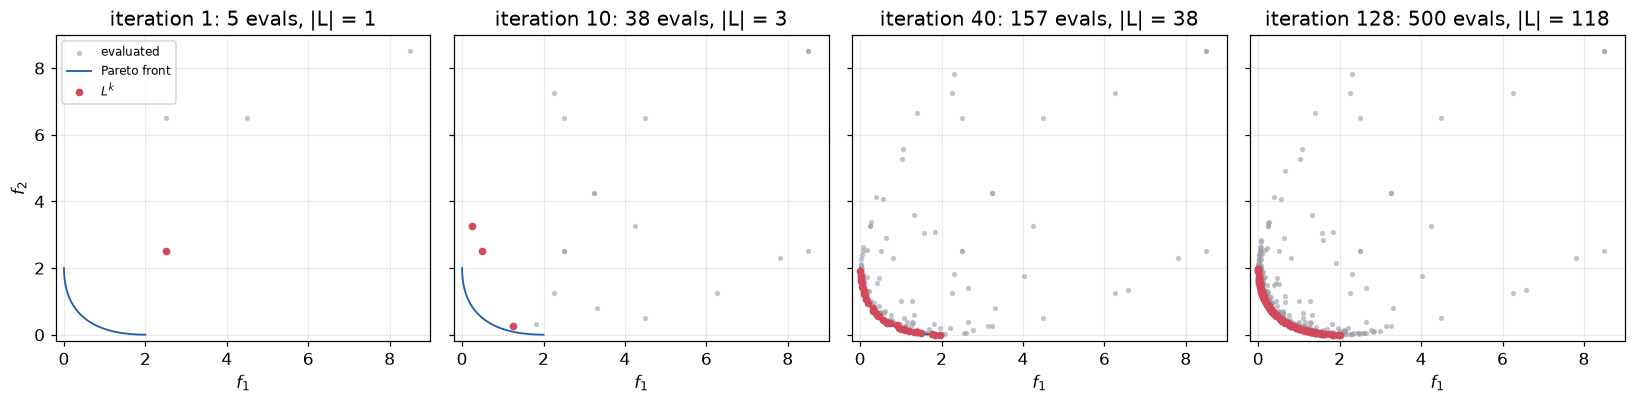

In [9]:
t = np.linspace(0, 1, 200)
snap_iters = [1, 10, 40, len(hist_sp)]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharex=True, sharey=True)
for ax, it in zip(axes, snap_iters):
    row = hist_sp.iloc[it - 1]
    seen = evals_sp.iloc[:row["evals"]]
    ax.scatter(seen["f1"], seen["f2"], s=6, color=COLORS["eval"], alpha=0.5, label="evaluated")
    ax.plot(2 * t ** 2, 2 * (1 - t) ** 2, color=COLORS["exact"], lw=1.2, label="Pareto front")
    ax.plot(*row["front"].T, "o", ms=4, color=COLORS["list"], label="$L^k$")
    ax.set(title=f"iteration {it}: {row['evals']} evals, |L| = {row['list_size']}", xlabel="$f_1$",
           xlim=(-0.2, 9), ylim=(-0.2, 9))
axes[0].set_ylabel("$f_2$")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

The list starts as a single point far from the front. The first iterations act like single-objective
MADS: poll points that **dominate** the centre replace it, and the list walks toward the front. Once it
reaches the front, most new points are **indifferent** to the list: it widens (extension) and fills in
(densifying). Notice that the dominated evaluations (grey) are concentrated close to the front: the poll
spends its budget where it matters.

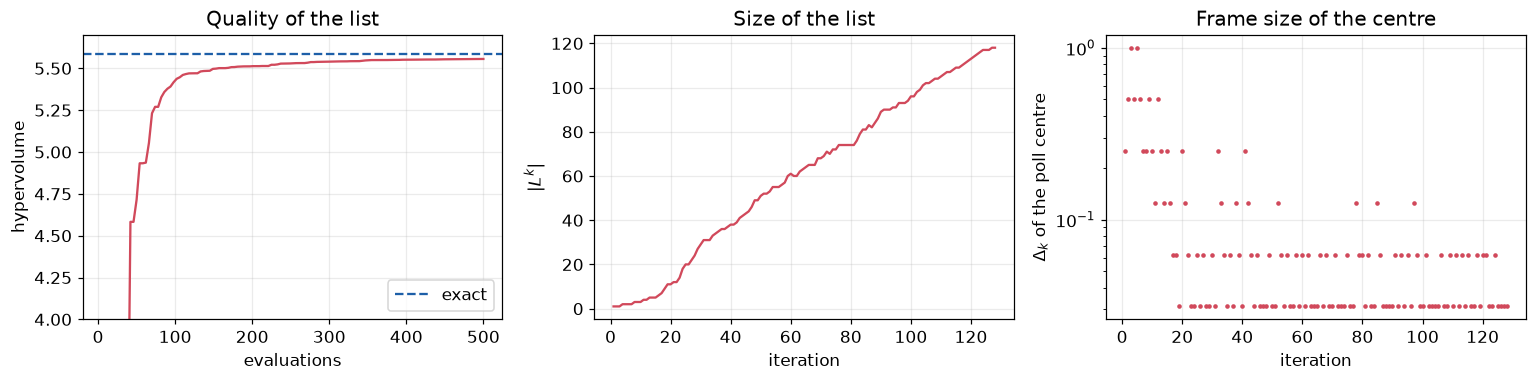

successful iterations: 5%


In [10]:
hv_curve = [hypervolume_2d(f, REF_SP) for f in hist_sp["front"]]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(hist_sp["evals"], hv_curve, color=COLORS["list"])
axes[0].axhline(HV_SP, color=COLORS["exact"], ls="--", label="exact")
axes[0].set(xlabel="evaluations", ylabel="hypervolume", title="Quality of the list", ylim=(4, 5.7))
axes[0].legend()
axes[1].plot(hist_sp["iteration"], hist_sp["list_size"], color=COLORS["list"])
axes[1].set(xlabel="iteration", ylabel="$|L^k|$", title="Size of the list")
axes[2].semilogy(hist_sp["iteration"], hist_sp["Delta_k"], ".", color=COLORS["list"], ms=4)
axes[2].set(xlabel="iteration", ylabel=r"$\Delta_k$ of the poll centre", title="Frame size of the centre")
plt.tight_layout()
plt.show()
print(f"successful iterations: {hist_sp['success'].mean():.0%}")

Two things differ from single-objective MADS:

- Very few iterations are **successful** (a poll point dominates the centre), yet the list keeps
  improving: indifferent points enter it through cases 2 and 3 of `update_list` even in an unsuccessful
  iteration.
- $\Delta_k$ does not decrease monotonically. Each point of the list has its own frame. After an
  unsuccessful poll the centre's frame shrinks, and Algorithm 3 then often moves to another point with a
  larger frame, or to a new point that entered with $\tau^{-1}\Delta$.

---
## 6. A non-convex front, and a constrained problem

**Fonseca-Fleming** ($[-4, 4]^2$), the non-convex front the weighted sum could not trace, and **Binh and
Korn** (BNH), a constrained problem:

$$
\text{BNH:}\quad \min\ \big(4x_1^2 + 4x_2^2,\ (x_1 - 5)^2 + (x_2 - 5)^2\big) \quad \text{s.t.}\quad
(x_1 - 5)^2 + x_2^2 \le 25,\quad (x_1 - 8)^2 + (x_2 + 3)^2 \ge 7.7,\quad x \in [0, 5] \times [0, 3].
$$

We compare DMulti-MADS with **random sampling** at the same budget of 500 evaluations, by hypervolume.

In [11]:
def fonseca_fleming(x):
    x = np.asarray(x, dtype=float)
    a = 1.0 / np.sqrt(len(x))
    return [1 - np.exp(-np.sum((x - a) ** 2)), 1 - np.exp(-np.sum((x + a) ** 2))], []


def bnh(x):
    x1, x2 = x
    return ([4 * x1 ** 2 + 4 * x2 ** 2, (x1 - 5) ** 2 + (x2 - 5) ** 2],
            [(x1 - 5) ** 2 + x2 ** 2 - 25, 7.7 - (x1 - 8) ** 2 - (x2 + 3) ** 2])


def random_sampling(problem, lb, ub, budget, seed=0):
    rs = np.random.default_rng(seed)
    X = np.asarray(lb) + rs.random((budget, len(lb))) * (np.asarray(ub) - np.asarray(lb))
    out = [problem(x) for x in X]
    F = np.array([f for f, _ in out])
    feasible = np.array([all(ci <= 0 for ci in c) for _, c in out])
    return F[feasible]


PROBLEMS = {"sphere pair": (sphere_pair, [-1.5, 1.5], [-2, -2], [2, 2], REF_SP),
            "Fonseca-Fleming": (fonseca_fleming, [0.0, 0.0], [-4, -4], [4, 4], np.array([1.0, 1.0])),
            "BNH": (bnh, [2.5, 1.5], [0, 0], [5, 3], np.array([140.0, 50.0]))}
runs, rows = {}, []
for name, (prob, x0, lb, ub, ref) in PROBLEMS.items():
    front, evals, hist = dmulti_mads(prob, x0, lb, ub, budget=500)
    F_rand = random_sampling(prob, lb, ub, 500)
    runs[name] = (front, evals, F_rand)
    rows.append(dict(problem=name, list_size=len(front), HV_dmulti_mads=hypervolume_2d(front[["f1", "f2"]], ref),
                     nd_random=int(nondominated(F_rand).sum()), HV_random=hypervolume_2d(F_rand, ref),
                     feasible_share=evals["feasible"].mean()))
pd.DataFrame(rows).set_index("problem")

,list_size,HV_dmulti_mads,nd_random,HV_random,feasible_share
problem,,,,,
sphere pair,118,5.55562,27,5.37984,0.956
Fonseca-Fleming,141,0.334716,15,0.250051,1
BNH,112,5237.05,91,5214.7,0.706


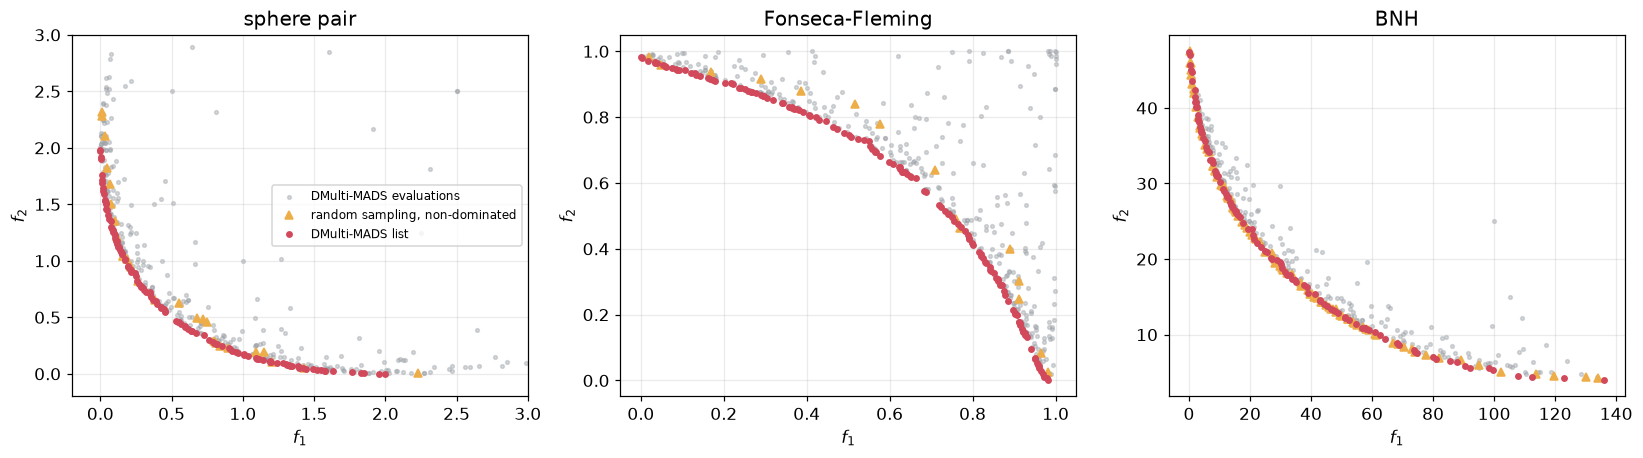

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (name, (front, evals, F_rand)) in zip(axes, runs.items()):
    feas = evals["feasible"]
    ax.scatter(evals.loc[feas, "f1"], evals.loc[feas, "f2"], s=6, color=COLORS["eval"], alpha=0.4,
               label="DMulti-MADS evaluations")
    Fr = F_rand[nondominated(F_rand)]
    ax.plot(*Fr[np.argsort(Fr[:, 0])].T, "^", ms=5, color=COLORS["random"], label="random sampling, non-dominated")
    ax.plot(front["f1"], front["f2"], "o", ms=3.5, color=COLORS["list"], label="DMulti-MADS list")
    ax.set(title=name, xlabel="$f_1$", ylabel="$f_2$")
axes[0].set(xlim=(-0.2, 3), ylim=(-0.2, 3))
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

What to notice:

- DMulti-MADS beats random sampling on all three problems at the same budget, by a wide margin on the
  non-convex front. Its list is larger and its points are **on** the front, not just near it. On BNH the
  margin is small because the problem has only two variables and a large feasible region, the best case
  for random sampling.
- On Fonseca-Fleming it traces the whole non-convex front, which the weighted sum could not. Dominance
  does not care about the shape of the front.
- On BNH the extreme barrier simply discards infeasible poll points. That is fine here because most of
  the box is feasible. When the feasible region is small, the extreme barrier wastes many evaluations,
  and a progressive barrier (as in single-objective MADS) is the better choice.

---
## 7. The knobs: $w^+$, $\tau$ and the budget

$w^+$ decides how many points can be poll centres; $\tau$ decides how fast the frames shrink (and grow).
Each setting below is run with 5 seeds on Fonseca-Fleming, budget 500; we report the mean and the spread
of the hypervolume.

In [13]:
prob, x0, lb, ub, ref = PROBLEMS["Fonseca-Fleming"]
rows = []
for label, kw in {"w+ = 0": dict(w_plus=0), "w+ = 1": dict(w_plus=1), "w+ = 3 (default)": dict(w_plus=3),
                  "w+ = 10": dict(w_plus=10), "tau = 0.25": dict(tau=0.25), "tau = 0.75": dict(tau=0.75),
                  "budget 200": dict(budget=200), "budget 2000": dict(budget=2000)}.items():
    kw = {"budget": 500, **kw}
    hv, size = [], []
    for seed in range(5):
        front, _, _ = dmulti_mads(prob, x0, lb, ub, seed=seed, **kw)
        hv.append(hypervolume_2d(front[["f1", "f2"]], ref))
        size.append(len(front))
    rows.append(dict(setting=label, HV_mean=np.mean(hv), HV_min=np.min(hv), HV_max=np.max(hv),
                     list_size_mean=np.mean(size)))
pd.DataFrame(rows).set_index("setting")

,HV_mean,HV_min,HV_max,list_size_mean
setting,,,,
w+ = 0,0.323563,0.321357,0.326027,58.6
w+ = 1,0.32943,0.32706,0.331179,78.4
w+ = 3 (default),0.334754,0.332587,0.335822,140.2
w+ = 10,0.336383,0.335579,0.337204,192.8
tau = 0.25,0.337024,0.336262,0.337637,203.2
tau = 0.75,0.32595,0.322843,0.331163,67.4
budget 200,0.326162,0.323047,0.328967,62.2
budget 2000,0.339636,0.339038,0.339878,415.8


On this small problem the differences are modest, but they have a clear direction:

- **$w^+$**: with $w^+ = 0$ only the points with the very largest frame can be centres, so the algorithm
  keeps returning to few points; a larger $w^+$ lets $\gamma$ choose among more points and spreads the
  list better. Beyond a few refinements it makes little difference.
- **$\tau$**: here a small $\tau$ works best. The frames reach the fine mesh needed to fill the front
  densely after few unsuccessful polls, so the list grows fast. A large $\tau$ shrinks slowly and spends
  more evaluations per point at coarse frames. On a multimodal problem a small $\tau$ can refine too
  early, around points that are not yet near the front.
- **Budget**: the hypervolume keeps increasing with the budget, with diminishing returns, as for the
  random sample in the previous notebook, but from a much higher starting level.

---
## Exercises

1. **Opportunism.** Stop the poll at the first point that dominates the centre (opportunistic poll). Does
   it save evaluations? What does it do to the size of the list?
2. **A search step.** Before the poll, evaluate 4 random points of the mesh around a random point of the
   list (Algorithm 1, step 3). Does the hypervolume improve on Fonseca-Fleming at the same budget?
3. **Three objectives.** Add $f^{(3)} = \|\mathbf{x} - (1, -1)\|^2$ to the sphere pair. Which functions must you
   change? (Hint: only the bookkeeping of `evals`; `update_list` and `gamma_indicator` work for any $p$.)
4. **A small feasible region.** Change the first BNH constraint to $(x_1 - 5)^2 + x_2^2 \le 4$ and start
   from a feasible point. What share of the evaluations is wasted by the extreme barrier?

---
## Takeaways

1. DMulti-MADS keeps a **list** of non-dominated incumbents, each with its own frame size, instead of one
   incumbent.
2. `updateList` rewards progress: points in the dominance or extension zones enter with a larger frame,
   points that only densify keep theirs, dominated points are discarded.
3. `selectCurrentIncumbent` polls around the point with the largest gap in the front ($\gamma$), among the
   points whose frame is within $w^+$ refinements of the largest.
4. At the same budget it approximates the front much better than random sampling, and it traces
   non-convex fronts that scalarizations miss. Constraints are handled by a barrier, as in MADS.